--- Sanity check ---
Mean of male trials before shuffling:  27.9868
Mean of male-labeled trials after:     27.9868
Equal within rounding error?           True

--- Real labels vs fake labels ---
Real labels  - mean male (label 1):    27.99
Real labels  - mean female (label 0):  30.79
Fake labels  - mean label 1:           29.23
Fake labels  - mean label 0:           29.55
Real difference (male - female):       -2.80
Fake difference (label 1 - label 0):   -0.32

--- Permutation results ---
Number of permutations:                10000
Observed difference (female - male):   2.80
Mean of the null distribution:         -0.01
Largest null difference:               4.58
Shuffles bigger than observed:         83 of 10000


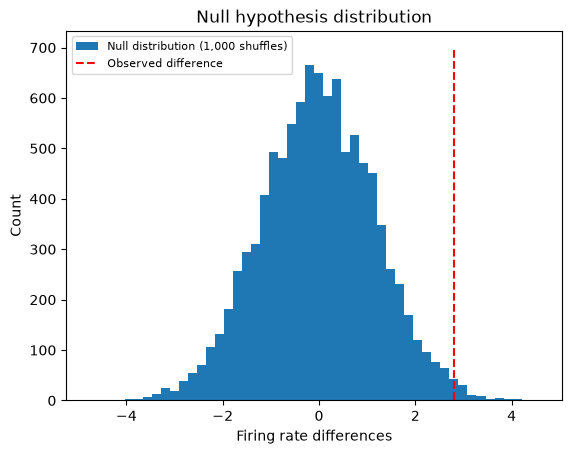

In [102]:
import numpy as np                     
import matplotlib.pyplot as plt         

# ---------------------------------------------------------------

# 1. Simulate the firing rates 
N = 100                                 # number of trials per condition

# male pictures
r = np.random.randn(N, 1)               # 100 random bell-curve numbers, as a column
r[r > 0] = np.log(1 + r[r > 0])         # log-transform only the positive numbers (skews the shape)
fr_males = 26 - r * 10                  # stretch by 10, flip the sign, shift to around 26

# female pictures
r = np.random.randn(N, 1)               # new random numbers (not a copy of the male ones)
r[r > 0] = np.log(1 + r[r > 0])         # same skew trick
fr_females = 30 - r * 10                # same, but shifted to around 30 (the built-in real effect)

# ---------------------------------------------------------------

# 2. Mix the trials and keep track of the conditions
allfr = np.concatenate((fr_males, fr_females), axis=0)  # stack: 100 male rows, then 100 female rows
neworder = np.random.permutation(N * 2)                 # random order of the numbers 0 to 199
conds = neworder.copy()                                 # separate copy that will become the labels
allfr = allfr[neworder]                                 # shuffle the data using that order
conds[neworder < N] = 1                                 # trials from the male half get label 1
conds[conds > 1] = 0                                    # everything else gets label 0 (female)

# sanity check: the male mean must be the same before and after shuffling
print("--- Sanity check ---")
print(f"Mean of male trials before shuffling:  {np.mean(fr_males):.4f}")
print(f"Mean of male-labeled trials after:     {np.mean(allfr[conds == 1]):.4f}")
print(f"Equal within rounding error?           {np.isclose(np.mean(fr_males), np.mean(allfr[conds == 1]))}")

# ---------------------------------------------------------------

# 3. One fake labeling 
fakeconds = np.random.permutation(N * 2)    # random order of 0 to 199 (labels only, data stays put)
fakeconds[fakeconds < N] = 1                # 100 random trials get label 1
fakeconds[fakeconds > 1] = 0                # the other 100 get label 0

mean_male_real = np.mean(allfr[conds == 1])         # real label 1 (male) average
mean_female_real = np.mean(allfr[conds == 0])       # real label 0 (female) average
mean_label1_fake = np.mean(allfr[fakeconds == 1])   # average of the trials the fake labels call "1"
mean_label0_fake = np.mean(allfr[fakeconds == 0])   # average of the trials the fake labels call "0"

print("\n--- Real labels vs fake labels ---")      # \n adds an empty line before the heading
print(f"Real labels  - mean male (label 1):    {mean_male_real:.2f}")
print(f"Real labels  - mean female (label 0):  {mean_female_real:.2f}")
print(f"Fake labels  - mean label 1:           {mean_label1_fake:.2f}")
print(f"Fake labels  - mean label 0:           {mean_label0_fake:.2f}")
print(f"Real difference (male - female):       {mean_male_real - mean_female_real:.2f}")
print(f"Fake difference (label 1 - label 0):   {mean_label1_fake - mean_label0_fake:.2f}")

# ---------------------------------------------------------------

# 4. Null hypothesis distribution
n_perms = 10000                              # how many shuffles to do
permdiffs = np.zeros(n_perms)               # storage: 1,000 zeros to be filled in

for permi in range(n_perms):                # repeat for permi = 0, 1, ..., 999
    fconds = np.random.permutation(N * 2)   # new random order each time
    fconds[fconds < N] = 1                  # 100 random trials get label 1
    fconds[fconds > 1] = 0                  # the rest get label 0
    permdiffs[permi] = np.mean(allfr[fconds == 0]) - np.mean(allfr[fconds == 1])  # store this shuffle's difference

# observed (real) difference, same formula and order as in the loop
obsval = np.mean(allfr[conds == 0]) - np.mean(allfr[conds == 1])
n_larger = np.sum(permdiffs > obsval)       # count shuffles with a bigger difference than the real one

print("\n--- Permutation results ---")
print(f"Number of permutations:                {n_perms}")
print(f"Observed difference (female - male):   {obsval:.2f}")
print(f"Mean of the null distribution:         {np.mean(permdiffs):.2f}")
print(f"Largest null difference:               {np.max(permdiffs):.2f}")
print(f"Shuffles bigger than observed:         {n_larger} of {n_perms}")

# ---------------------------------------------------------------

# 5. Plot (Figure 15.3)
plt.hist(permdiffs, 50, label='Null distribution (1,000 shuffles)')
plt.plot([obsval, obsval], plt.ylim(), '--', color='red', label='Observed difference')
plt.xlabel('Firing rate differences')
plt.ylabel('Count')
plt.title('Null hypothesis distribution')
plt.legend(loc='upper left', fontsize=8)
plt.show()

In [103]:
z = (obsval - np.mean(permdiffs)) / np.std(permdiffs, ddof=1)
print(f"Z-score of the observed difference: {z:.5f}")

Z-score of the observed difference: 2.39184


In [104]:
from scipy.stats import norm

p = 1 - norm.cdf(np.abs(z)) #The formula 1 - cdf(z) only gives a sensible p-value when z is positive
print(f"P-value of the observed difference: {p:.5f}")

P-value of the observed difference: 0.00838


In [105]:
#Using abs(z) treats the left tail like the right tail, so the p-value is correct for both.
for zval in (3, -3):
    p_with_abs = 1 - norm.cdf(np.abs(zval))
    p_without_abs = 1 - norm.cdf(zval)
    print(f"z = {zval:2d}   with abs: {p_with_abs:.5f}   without abs: {p_without_abs:.5f}")

z =  3   with abs: 0.00135   without abs: 0.00135
z = -3   with abs: 0.00135   without abs: 0.99865


In [106]:
#This p-value is one-tailed. For a two-tailed p-value, multiply by two.
p_two_tailed = 2 * p
print(f"Two-tailed P-value of the observed difference: {p_two_tailed:.5f}")

Two-tailed P-value of the observed difference: 0.01676


In [107]:
p_count = np.sum(permdiffs > obsval) / n_perms
print(f"p-value, counting method:{p_count:.5f}")

p-value, counting method:0.00830
